# F1 lap-time prediction across the 2026 regulation change
## Notebook 02 - baselines, regime shift, and few-shot recovery

We train on the 2022-2025 cars and ask two things: how much does lap-time error jump when we cross into the 2026 regulation change (new power units, active aero, no DRS), and how many 2026 races does the model need before it recovers?

**Rules we hold to:** never split laps randomly (laps from one race are highly correlated and would leak), so every split is **by race or by season**, with a fixed seed. The target is `lap_delta_s` (lap time minus the race median), so circuit length is already normalised out.

Three models of increasing complexity, all wired through the `f1lap` package:
1. **Physics baseline** - linear regression on per-compound tyre age and a fuel proxy (laps remaining), following Heilmeier's lap-time decomposition.
2. **XGBoost** - gradient boosting on the full encoded feature set.
3. **Residual model** - XGBoost trained on the physics baseline's residuals; the bet is that physical relationships transfer across the regulation change better than raw patterns.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.path.abspath('src'))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, GridSearchCV
import xgboost as xgb

from f1lap.features import encode_features
from f1lap.models import SEED, make_xgb, metrics, breakdown, PhysicsBaseline, ResidualModel

np.random.seed(SEED)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
os.makedirs('figures', exist_ok=True)

df = pd.read_csv('data/clean_laps.csv.gz')
X_all = encode_features(df)             # one aligned 20-column matrix, sliced per split
y_all = df['lap_delta_s']
FEATURE_COLS = list(X_all.columns)
print('Clean laps:', df.shape, '| feature matrix:', X_all.shape)
print(df.season.value_counts().sort_index().rename('laps').to_frame().T.to_string())

Clean laps: (89737, 24) | feature matrix: (89737, 20)
season   2022   2023   2024   2025   2026
laps    15140  17788  20156  20131  16522


### Model wiring

`X_all` is built **once** on the full clean table so the one-hot columns (compound, team lineage including the unseen Cadillac) line up across every split; each experiment just slices it by a race/season mask. That alignment is what lets a model trained on 2022-2025 score 2026 laps without column mismatches.

### Experiment 5 - hyperparameter tuning (done first so every experiment uses the tuned model)

XGBoost is tuned with **GroupKFold grouped by race**, on the **training seasons only (2022-2025)**. Grouping by race keeps all of a race's laps in the same fold, so nothing leaks across the split.

In [2]:
train_era = df.season < 2026
groups = pd.factorize(df['season'].astype(str) + '_' + df['event'])[0]
gkf = GroupKFold(n_splits=5)
grid = {'max_depth':[4,6], 'n_estimators':[300,600], 'learning_rate':[0.03,0.08]}
search = GridSearchCV(make_xgb(n_jobs=1), grid, scoring='neg_mean_absolute_error',
                      cv=gkf, n_jobs=-1)
search.fit(X_all[train_era], y_all[train_era].values, groups=groups[train_era.to_numpy()])
XGB_PARAMS = dict(search.best_params_)
print('Chosen XGBoost params:', XGB_PARAMS)
print('Best grouped-CV MAE: %.4f s' % (-search.best_score_))

Chosen XGBoost params: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 300}
Best grouped-CV MAE: 0.5790 s


The chosen parameters above are used for the XGBoost and residual models in **every** experiment below. Grouping by race is the important bit: a random CV split would put laps from the same race in both train and validation and report an over-optimistic score.

In [3]:
def fit_predict(name, tr_mask, te_mask):
    dtr, Xtr, ytr = df[tr_mask], X_all[tr_mask], y_all[tr_mask].values
    dte, Xte = df[te_mask], X_all[te_mask]
    if name == 'Physics':  return PhysicsBaseline().fit(dtr, ytr).predict(dte)
    if name == 'XGBoost':  return make_xgb(**XGB_PARAMS).fit(Xtr, ytr).predict(Xte)
    if name == 'Residual': return ResidualModel(**XGB_PARAMS).fit(dtr, Xtr, ytr).predict(dte, Xte)

MODELS = ['Physics', 'XGBoost', 'Residual']
COLORS = {'Physics':'#718096', 'XGBoost':'#2b6cb0', 'Residual':'#c53030'}

def evaluate_split(tr_mask, te_mask):
    yte = y_all[te_mask].values
    return pd.DataFrame({n: metrics(yte, fit_predict(n, tr_mask, te_mask)) for n in MODELS}).T

### Experiment 1 - in-era check (train 2022-2024, test 2025)

A within-distribution sanity check: if the pipeline is sound, the error here should be in the same ballpark as the published **F1 StratLab** benchmark (XGBoost lap-time model, MAE ~0.392 s, trained pre-2026).

In [4]:
tr = df.season.isin([2022,2023,2024]); te = df.season == 2025
inera = evaluate_split(tr, te).round(3)
print('In-era (train 2022-2024, test 2025), MAE/RMSE in seconds:')
inera

In-era (train 2022-2024, test 2025), MAE/RMSE in seconds:


,MAE,RMSE
Physics,0.758,1.003
XGBoost,0.587,0.789
Residual,0.582,0.786


**Read:** XGBoost and the residual model land at **~0.59 s and ~0.58 s** MAE, with the physics baseline a clear floor at ~0.76 s. That's higher than the ~0.39 s F1 StratLab figure, but it's a loose reference rather than a like-for-like number: StratLab predicts raw lap time on 2023-2025, while we predict the race-median-relative *delta* (an already-normalised, harder target). What matters is that the pipeline is sound and stable - the two boosted models roughly match each other and sit well below the physics floor. This ~0.58 s is the in-era bar we judge the 2026 jump against.

### Experiments 2 & 3 - normal drift (control) vs the regime shift

We measure every transition the **same way** - train on all prior seasons, test on the next unseen season. 2024 and 2025 are normal years (the control for year-to-year drift); 2026 is the regulation change. The gap between the 2026 error and the 2024/2025 trend is the part attributable to the new rules, not to normal drift.

In [5]:
transitions = [([2022,2023], 2024), ([2022,2023,2024], 2025), ([2022,2023,2024,2025], 2026)]
rows = []
for tr_seasons, te_season in transitions:
    ev = evaluate_split(df.season.isin(tr_seasons), df.season == te_season)
    for n in MODELS:
        rows.append({'test_season':te_season,'model':n,'MAE':ev.loc[n,'MAE'],'RMSE':ev.loc[n,'RMSE']})
season_mae = pd.DataFrame(rows)
piv = season_mae.pivot(index='test_season', columns='model', values='MAE').round(3)
print('MAE by test season (2024-2025 = normal drift, 2026 = regime change):')
piv

MAE by test season (2024-2025 = normal drift, 2026 = regime change):


model,Physics,Residual,XGBoost
test_season,,,
2024,0.829,0.634,0.629
2025,0.758,0.582,0.587
2026,1.137,0.794,0.786


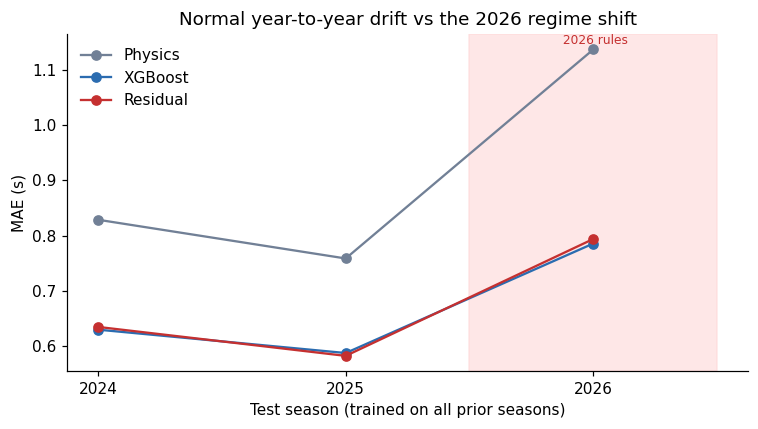

In [6]:
fig, ax = plt.subplots(figsize=(7,4))
for n in MODELS:
    s = season_mae[season_mae.model==n]
    ax.plot(s.test_season, s.MAE, marker='o', label=n, color=COLORS[n])
ax.axvspan(2025.5, 2026.5, color='#fed7d7', alpha=0.6)
ax.text(2026, ax.get_ylim()[1], ' 2026 rules', va='top', ha='center', fontsize=8, color='#c53030')
ax.set_xticks([2024,2025,2026]); ax.set_xlabel('Test season (trained on all prior seasons)')
ax.set_ylabel('MAE (s)'); ax.set_title('Normal year-to-year drift vs the 2026 regime shift')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/05_mae_by_test_season.png', dpi=150); plt.show()

**Figure 05.** The two normal transitions sit around **0.59-0.63 s** for the boosted models - that's the baseline year-to-year drift. At 2026 the error jumps to **~0.79 s**, roughly **+25%** above the normal level, and that excess is the regime-shift effect: the share the new power units, active aero and loss of DRS add on top of a normal year. Notably the residual (physics-informed) model tracks plain XGBoost almost exactly (0.794 vs 0.786 at 2026), so the physical priors did **not** buy measurable cross-era robustness here - the two boosted models degrade together, while the physics baseline is just a weaker floor throughout.

#### Regime shift in detail - breakdowns by compound, team lineage, and circuit

For the 2026 test we break error down and flag the genuinely **unseen** entities: the **Cadillac** team (new in 2026, no lineage) and the **Madrid** circuit (new track).

In [7]:
tr = df.season < 2026; te = df.season == 2026
yte = y_all[te].values
preds = {n: fit_predict(n, tr, te) for n in MODELS}
overall = pd.DataFrame({n: metrics(yte, preds[n]) for n in MODELS}).T.round(3)
print('Regime shift overall (train 2022-2025, test 2026):'); print(overall.to_string())

best = min(MODELS, key=lambda n: metrics(yte, preds[n])['MAE'])
dte = df[te]
bd_cmp  = breakdown(dte, yte, preds[best], 'compound')
bd_team = breakdown(dte, yte, preds[best], 'team_lineage', unseen={'Cadillac'})
bd_circ = breakdown(dte, yte, preds[best], 'circuit', unseen={'Madrid'})
print('\nBreakdowns use the best 2026 model: %s' % best)
print('\nBy compound:');            print(bd_cmp.to_string(index=False))
print('\nBy team lineage:');        print(bd_team.to_string(index=False))
print('\nBy circuit (worst 6):');   print(bd_circ.head(6).to_string(index=False))
overall

Regime shift overall (train 2022-2025, test 2026):
            MAE   RMSE
Physics   1.137  1.475
XGBoost   0.786  1.095
Residual  0.794  1.102

Breakdowns use the best 2026 model: XGBoost

By compound:
compound    n   MAE  RMSE  unseen
    SOFT 3789 0.835 1.199   False
  MEDIUM 5717 0.781 1.061   False
    HARD 7016 0.762 1.063   False

By team lineage:
   team_lineage    n   MAE  RMSE  unseen
       Cadillac 1251 1.559 2.000    True
   Aston Martin 1066 1.340 1.762   False
       Mercedes 1684 0.730 0.926   False
       Williams 1498 0.727 1.037   False
        McLaren 1529 0.713 0.893   False
    Sauber/Audi 1498 0.700 0.921   False
        Ferrari 1672 0.693 0.866   False
   Haas F1 Team 1531 0.688 0.961   False
         Alpine 1630 0.656 0.878   False
Red Bull Racing 1533 0.596 0.785   False
   Racing Bulls 1630 0.581 0.816   False

By circuit (worst 6):
   circuit    n   MAE  RMSE  unseen
    Madrid  953 1.268 1.716    True
    Monaco 1135 1.216 1.481   False
  Canadian  903 1.131

,MAE,RMSE
Physics,1.137,1.475
XGBoost,0.786,1.095
Residual,0.794,1.102


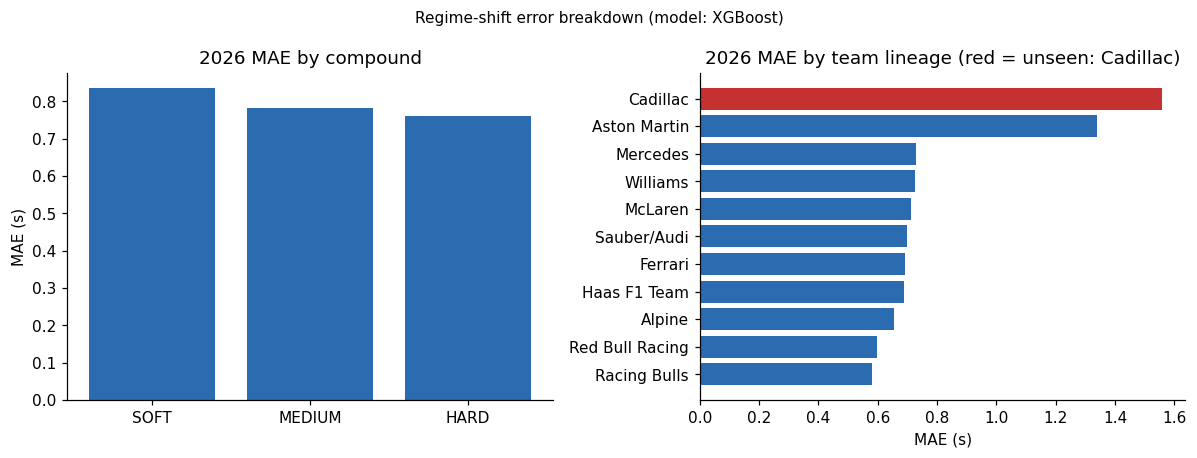

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11,4.2))
axs[0].bar(bd_cmp.compound, bd_cmp.MAE, color='#2b6cb0')
axs[0].set_title('2026 MAE by compound'); axs[0].set_ylabel('MAE (s)')
ct = ['#c53030' if u else '#2b6cb0' for u in bd_team.unseen]
axs[1].barh(list(bd_team.team_lineage)[::-1], list(bd_team.MAE)[::-1], color=ct[::-1])
axs[1].set_title('2026 MAE by team lineage (red = unseen: Cadillac)'); axs[1].set_xlabel('MAE (s)')
fig.suptitle('Regime-shift error breakdown (model: %s)' % best, fontsize=10)
plt.tight_layout(); plt.savefig('figures/07_regime_breakdown.png', dpi=150); plt.show()

**Figure 07.** Error concentrates exactly where a regime shift predicts. The **unseen** entities are worst: **Cadillac** at 1.56 s (no lineage history, so the model falls back to an average team) and the new **Madrid** circuit at 1.27 s (worst of any track, in the table above). Among compounds, **SOFT** is hardest (0.84 s) - the fastest-degrading, most situational tyre. The real surprise is **Aston Martin** (1.34 s), a *seen* team that's second-worst: a sign its 2026 car changed enough that 2022-2025 patterns no longer describe it. That's the regime shift showing up even in a familiar team, not just the brand-new one.

### Experiment 4 - few-shot recovery

Now we let the model see a little 2026: add the first **k** 2026 races to training (k = 0, 1, 2, 4, 8) and test on the remaining 2026 races. Because early/late 2026 races are at different circuits, we repeat over **5 random race orderings** and report mean +/- spread. (Caveat: the test set shrinks as k grows, from 18 races at k=0 to 10 at k=8 - the spread captures that.)

In [9]:
races_2026 = df.loc[df.season==2026,'event'].unique()
K = [0,1,2,4,8]
rng = np.random.RandomState(SEED)
orderings = [rng.permutation(races_2026) for _ in range(5)]
rows = []
for oi, order in enumerate(orderings):
    for k in K:
        add = set(order[:k]); rest = [r for r in races_2026 if r not in add]
        tr = (df.season<2026) | ((df.season==2026) & df.event.isin(add))
        te = (df.season==2026) & df.event.isin(rest)
        yte = y_all[te].values
        for n in MODELS:
            rows.append({'ordering':oi,'k':k,'model':n,'MAE':metrics(yte, fit_predict(n,tr,te))['MAE']})
fs = pd.DataFrame(rows)
fs_summary = fs.groupby(['k','model']).MAE.agg(['mean','std']).reset_index()
print('Mean MAE (s) by k and model:')
fs_summary.pivot(index='k', columns='model', values='mean').round(3)

Mean MAE (s) by k and model:


model,Physics,Residual,XGBoost
k,,,
0,1.137,0.794,0.786
1,1.133,0.755,0.742
2,1.138,0.756,0.744
4,1.144,0.752,0.737
8,1.178,0.770,0.753


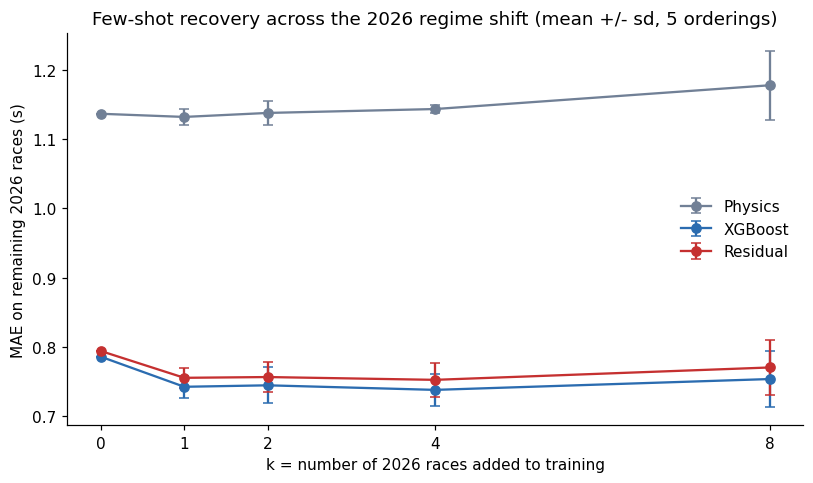

In [10]:
fig, ax = plt.subplots(figsize=(7.5,4.5))
for n in MODELS:
    s = fs_summary[fs_summary.model==n].sort_values('k')
    ax.errorbar(s.k, s['mean'], yerr=s['std'].fillna(0), marker='o', capsize=3, label=n, color=COLORS[n])
ax.set_xlabel('k = number of 2026 races added to training')
ax.set_ylabel('MAE on remaining 2026 races (s)')
ax.set_title('Few-shot recovery across the 2026 regime shift (mean +/- sd, 5 orderings)')
ax.set_xticks(K); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/06_few_shot_recovery.png', dpi=150); plt.show()

**Figure 06.** Most of the recovery arrives immediately: the first 2026 race drops MAE from **0.79 s (k=0)** to **~0.74 s**, and then the curve flattens - k = 2, 4, 8 all hover around **0.74-0.75 s**, with the spread widening as the test set shrinks (18 races at k=0 down to 10 at k=8). The honest finding: a handful of 2026 races gives a quick *partial* fix but does **not** get back to the in-era ~0.59 s bar from Experiment 1. Eight races isn't enough to fully re-learn the 2026 regime - closing the rest of the gap would need more of the season than has been run yet, which is itself the answer to "how many races does it take." The physics baseline barely moves with k, as expected: its handful of parameters can't absorb new-era structure.

### Experiment 6 - SHAP diagnosis: which relationships changed?

We compare **TreeSHAP** feature attributions for a model trained on 2022-2025 against one that also sees 2026, both explained on the 2026 laps. SHAP values come straight from **XGBoost's native `pred_contribs`** (the same TreeSHAP algorithm the `shap` library wraps), so there's no extra dependency. Features whose importance moves are the relationships the regulation change altered.

In [11]:
m_pre  = make_xgb(**XGB_PARAMS).fit(X_all[df.season<2026], y_all[df.season<2026].values)
m_post = make_xgb(**XGB_PARAMS).fit(X_all, y_all.values)
dm = xgb.DMatrix(X_all[df.season==2026])
def mean_abs_shap(m):
    c = m.get_booster().predict(dm, pred_contribs=True)[:, :-1]   # drop the bias column
    return pd.Series(np.abs(c).mean(0), index=FEATURE_COLS)
shap_cmp = pd.DataFrame({'2022-2025': mean_abs_shap(m_pre), 'incl_2026': mean_abs_shap(m_post)})
shap_cmp['change'] = (shap_cmp['incl_2026'] - shap_cmp['2022-2025'])
top = shap_cmp.sort_values('incl_2026', ascending=False).head(12)
print('Mean |SHAP| on 2026 laps (top 12 features):')
top.round(4)

Mean |SHAP| on 2026 laps (top 12 features):


,2022-2025,incl_2026,change
position,0.4842,0.5935,0.1093
fuel_proxy,0.5778,0.5364,-0.0414
stint,0.2283,0.2402,0.0119
tyre_age,0.1904,0.1649,-0.0255
team_Cadillac,0.0000,0.0862,0.0862
air_temp_c,0.0889,0.0752,-0.0137
track_temp_c,0.0496,0.0641,0.0146
team_Red Bull Racing,0.0298,0.0326,0.0028
team_Mercedes,0.0214,0.0283,0.0069
team_Ferrari,0.0223,0.0274,0.0052


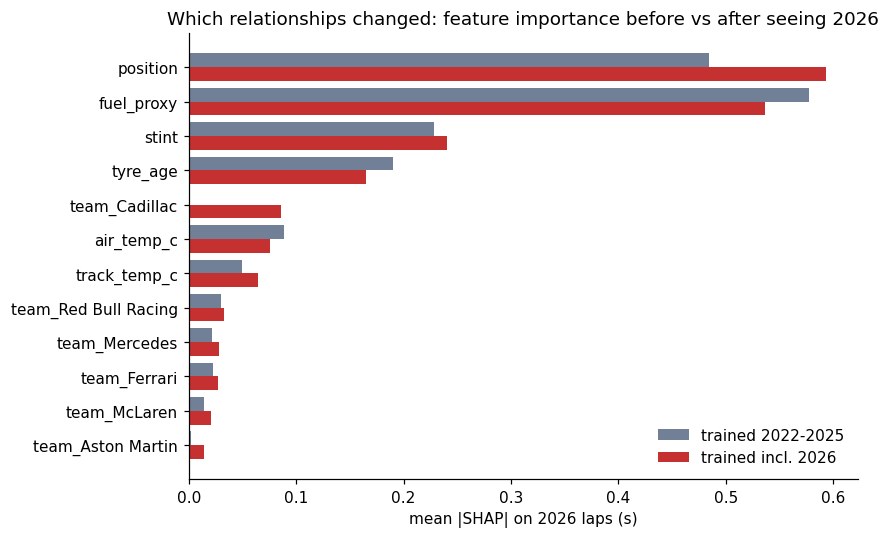

In [12]:
t = top.sort_values('incl_2026')
yy = np.arange(len(t)); h = 0.4
fig, ax = plt.subplots(figsize=(8,5))
ax.barh(yy+h/2, t['2022-2025'], height=h, label='trained 2022-2025', color='#718096')
ax.barh(yy-h/2, t['incl_2026'], height=h, label='trained incl. 2026', color='#c53030')
ax.set_yticks(yy); ax.set_yticklabels(t.index); ax.set_xlabel('mean |SHAP| on 2026 laps (s)')
ax.set_title('Which relationships changed: feature importance before vs after seeing 2026')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('figures/08_shap_comparison.png', dpi=150); plt.show()

**Figure 08.** Once 2026 is in training the attribution shifts in a specific way: the model leans **more on `position`** (mean |SHAP| 0.48 -> 0.59, the biggest rise of any existing feature) and picks up **`team_Cadillac`** from zero (it only exists once 2026 is included), while **`fuel_proxy` and `tyre_age` importance slightly *fall***. That's a little surprising given notebook 01 showed 2026 within-stint pace evolving differently - but it fits the normalised target: subtracting the race median already soaks up much of the tyre/fuel signal, so the relationship that most visibly changed across the regime is **field order and the new team**, not the raw degradation curve. 2026's wider spread is more about *where you run in the field* than about the tyre.

### Overall summary

In [13]:
summary = pd.DataFrame({
    'In-era 2025':         inera['MAE'],
    'Regime 2026 (k=0)':   overall['MAE'],
    'Few-shot 2026 (k=8)': fs_summary[fs_summary.k==8].set_index('model')['mean'].round(3),
})
print('MAE (s) across the key experiments:')
summary.round(3)

MAE (s) across the key experiments:


,In-era 2025,Regime 2026 (k=0),Few-shot 2026 (k=8)
Physics,0.758,1.137,1.178
Residual,0.582,0.794,0.770
XGBoost,0.587,0.786,0.753


### Status update

**What's done.** The full first modelling iteration: three models (physics baseline, XGBoost, residual) wired through the `f1lap` package; race-grouped GroupKFold tuning; the in-era check (~0.58 s); the normal-drift control vs the 2026 regime shift (a clean ~+25% jump) with per-compound / per-team / per-circuit breakdowns flagging Cadillac (1.56 s) and Madrid (1.27 s); the few-shot recovery curve over 5 race orderings; and a TreeSHAP before/after diagnosis. Four new figures saved to `figures/`.

**What's left.** Separate the fuel/tyre confound in 2026 (the stint-pace plot mixes them); widen the tuning grid (the optimum sat at the regularised corner - shallow depth, slow learning - so smaller/more-regularised may still help); add target-encoded circuit/driver features and compare; try an LSTM over stints as a stretch model; and report the absolute (non-normalised) slowdown alongside the relative target.

**What was hardest.** Keeping the splits honest - everything is by race or season, the feature matrix is built once so columns align across eras, and tuning is grouped by race so nothing leaks. Getting SHAP without the `shap` library (which broke the numpy stack) by using XGBoost's native `pred_contribs` was the other fiddly bit.

**What was surprising.** Three things. (1) The physics-informed **residual model gave no edge** over plain XGBoost - they tie everywhere, so physical priors didn't transfer better across the regime than learned patterns. (2) **Few-shot plateaus** well above the in-era bar: the first 2026 race helps a lot, but eight still leave ~0.75 s vs ~0.59 s in-era. (3) SHAP says the relationship that changed most is **`position` and the new team, not tyre degradation** - the normalised target hides the tyre-curve change that was so visible in notebook 01.